# Analyse d'un portefeuille de trois actions du CAC 40
**Objectif :** mesurer le rendement et le risque d'Airbus, LVMH et L'Oréal, 
puis étudier l'effet de la diversification dans un portefeuille à poids égaux.

**Outils :** Python, pandas, NumPy, matplotlib, yfinance

**Période :** janvier 2024 à octobre 2026 (cours de clôture ajustés, données journalières)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

## 1. Récupération des données
Téléchargement des cours de clôture ajustés (dividendes et divisions d'actions inclus). 
Les données sont sauvegardées en CSV pour que l'analyse reste reproductible.

In [2]:
tickers = ["AIR.PA", "MC.PA", "OR.PA"]
prix = yf.download(tickers, start="2024-01-01", end="2026-10-10")["Close"]
prix.to_csv("prix.csv")      # sauvegarde : fige les données

print(prix.shape)
prix.head()

[*********************100%***********************]  3 of 3 completed


(709, 3)


Ticker,AIR.PA,MC.PA,OR.PA
Date,,,
2024-01-02,133.345261,681.810913,421.027679
2024-01-03,129.456650,655.783264,416.284241
2024-01-04,131.551971,658.046509,414.908661
2024-01-05,131.853989,649.653625,411.967712
2024-01-08,135.157425,651.916809,415.952209


## 2. Rendements journaliers
Le rendement d'un jour est la variation du cours par rapport à la veille. La première ligne est supprimée, faute de cours précédent.

In [3]:
rend = prix.pct_change().dropna()
rend.head()

Ticker,AIR.PA,MC.PA,OR.PA
Date,,,
2024-01-03,-0.029162,-0.038174,-0.011266
2024-01-04,0.016186,0.003451,-0.003304
2024-01-05,0.002296,-0.012754,-0.007088
2024-01-08,0.025054,0.003484,0.009672
2024-01-09,-0.000559,-0.015333,0.004676


## 3. Rendement et risque annualisés
- Rendement annualisé = rendement journalier moyen × 252 (jours de bourse)
- Volatilité annualisée = écart-type journalier × √252
- Ratio rendement/risque = rendement annualisé / volatilité annualisée (taux sans risque supposé nul)

In [4]:
resume = pd.DataFrame({
    "Rendement": rend.mean() * 252,
    "Volatilité": rend.std() * np.sqrt(252),
})
resume["Rendement/Risque"] = resume["Rendement"] / resume["Volatilité"]
resume.round(3)

,Rendement,Volatilité,Rendement/Risque
Ticker,,,
AIR.PA,0.159,0.272,0.585
MC.PA,-0.163,0.302,-0.538
OR.PA,-0.006,0.243,-0.024


## 4. Corrélations
Plus la corrélation entre deux actions est faible, plus leurs variations se compensent dans un portefeuille.

In [5]:
rend.corr().round(2)

Ticker,AIR.PA,MC.PA,OR.PA
Ticker,,,
AIR.PA,1.00,0.31,0.28
MC.PA,0.31,1.00,0.56
OR.PA,0.28,0.56,1.00


## 5. Portefeuille à poids égaux
Un tiers du capital dans chaque action, avec un rééquilibrage quotidien (hypothèse simplificatrice, sans frais de transaction).

In [6]:
rend_ptf = rend.mean(axis=1)

vol_ptf = rend_ptf.std() * np.sqrt(252)
rdt_ptf = rend_ptf.mean() * 252

print("Rendement annualisé :", round(rdt_ptf, 3))
print("Volatilité annualisée :", round(vol_ptf, 3))
print("Moyenne des volatilités des 3 actions :", round(resume["Volatilité"].mean(), 3))

Rendement annualisé : -0.003
Volatilité annualisée : 0.209
Moyenne des volatilités des 3 actions : 0.272


## 6. Évolution en base 100

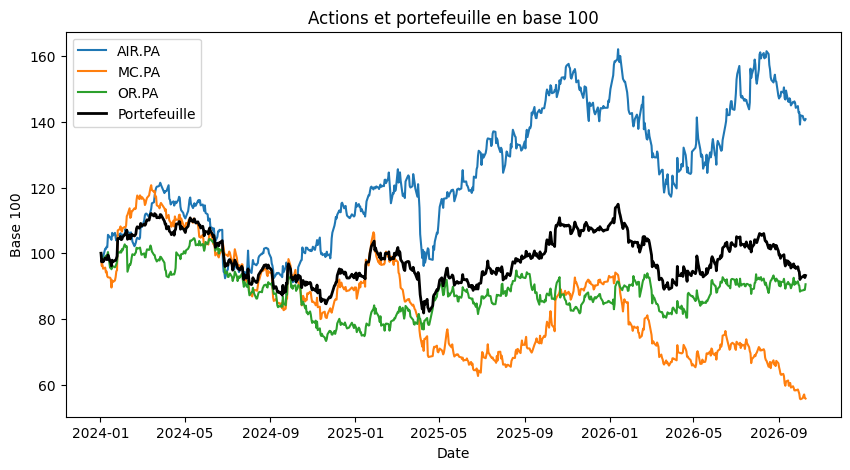

In [7]:
base100 = prix / prix.iloc[0] * 100
valeur_ptf = (1 + rend_ptf.reindex(prix.index, fill_value=0)).cumprod() * 100

plt.figure(figsize=(10, 5))
for ticker in base100.columns:
    plt.plot(base100[ticker], label=ticker)
plt.plot(valeur_ptf, label="Portefeuille", color="black", linewidth=2)

plt.title("Actions et portefeuille en base 100")
plt.xlabel("Date")
plt.ylabel("Base 100")
plt.legend()
plt.show()

In [8]:
drawdown = valeur_ptf / valeur_ptf.cummax() - 1
print("Drawdown maximal du portefeuille :", round(drawdown.min(), 3))
print("Ratio rendement/risque du portefeuille :", round(rdt_ptf / vol_ptf, 3))

Drawdown maximal du portefeuille : -0.27
Ratio rendement/risque du portefeuille : -0.016


## Conclusion

**Rendement et risque.** Sur la période étudiée (janvier 2024 à octobre 2026), Airbus est la seule des trois actions à afficher un rendement annualisé nettement positif (+15,9 %), avec un ratio rendement/risque de 0,59. LVMH est la plus volatile (30,2 %) et la moins performante (-16,3 %, ratio de -0,54) : sur cet échantillon, le risque pris sur LVMH n'a pas été récompensé. L'Oréal, la moins volatile (24,3 %), termine proche de l'équilibre (-0,6 %).

**Corrélations.** LVMH et L'Oréal sont les actions les plus corrélées (0,56), ce qui s'explique par leur appartenance au même univers du luxe et de la consommation. Airbus est faiblement corrélé aux deux autres (0,31 et 0,28) : c'est l'action qui diversifie le plus.

**Effet de la diversification.** Le portefeuille à poids égaux affiche une volatilité annualisée de 20,9 %, inférieure à celle de chacune des trois actions (24,3 % à 30,2 %) et de 6,3 points à leur moyenne (27,2 %). Son rendement annualisé (-0,3 %) correspond à la moyenne de celui des trois actions : à rendement moyen équivalent, le risque est donc nettement plus faible. En contrepartie, le portefeuille renonce à la performance d'Airbus seul.

**Limites.** La diversification protège moins lors des fortes baisses de marché : en avril 2025, les trois actions reculent simultanément et le portefeuille chute avec elles. L'analyse porte sur seulement trois actions issues de deux secteurs, sur une période courte, avec un rééquilibrage quotidien supposé et sans frais de transaction. Les performances passées ne préjugent pas des performances futures.

**Pistes d'amélioration.** Élargir l'échantillon à d'autres secteurs, tester des pondérations différentes de l'égalité, et compléter l'analyse par le ratio de Sharpe avec un taux sans risque réel et par le drawdown maximal du portefeuille.